# Milestone 3: Exploratory Data Analysis

**Project:** 

Customer and Sales Intelligence for a Kenyan Retailer

**Period covered:** 

1 January 2025 to 31 October 2026 (22 months of observed sales)

## Purpose
Milestone 2 produced eight cleaned tables. This notebook merges them into one analysis table and explores it in the order the capstone asks for:

| Section | What it covers | Business questions |
|---|---|---|
| 1 | Load the cleaned tables | n/a |
| 2 | Merge into one table and check the join | n/a |
| 3 | Distributions | Q1, Q4 |
| 4 | Trends over time and promotion months | Q7, Q10 |
| 5 | Seasonality: day of week, month, public holidays, inflation | Q3, Q11 |
| 6 | Segments: customers, stores and counties, products, payment methods, customer activity | Q1, Q2, Q4, Q5, Q6, Q8, Q9 |
| 7 | Summary of findings and limitations | all |



**Data note.** 
Sales, customers, stores, products and promotions are synthetic tables (see Milestone 1). Patterns that look unusually clean are reported as such rather than treated as real-world behaviour.

In [1]:
###  Load the cleaned tables All eight tables come from data/processed, written at the end of Milestone 2


import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.figsize": (10, 4.5), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})
os.makedirs("../reports/figures", exist_ok=True)

def save(name):
    plt.tight_layout()
    plt.savefig(f"../reports/figures/{name}.png", dpi=150)
    plt.show()

p = "../data/processed/"
sales      = pd.read_csv(p + "sales_clean.csv",      parse_dates=["transaction_date"])
customers  = pd.read_csv(p + "customers_clean.csv",  parse_dates=["signup_date"])
stores     = pd.read_csv(p + "stores_clean.csv",     parse_dates=["opening_date"])
products   = pd.read_csv(p + "products_clean.csv")
promotions = pd.read_csv(p + "promotions_clean.csv")
census     = pd.read_csv(p + "census_clean.csv")
inflation  = pd.read_csv(p + "inflation_clean.csv",  parse_dates=["month_start"])
holidays   = pd.read_csv(p + "holidays_clean.csv",   parse_dates=["Date"])

tables = {"sales": sales, "customers": customers, "stores": stores, "products": products,
          "promotions": promotions, "census": census, "inflation": inflation,
          "holidays": holidays}

for name, table in tables.items():
    print(name, table.shape)
    print("   ", table.columns.tolist())

sales (113168, 18)
    ['transaction_id', 'transaction_date', 'customer_id', 'store_id', 'product_id', 'quantity', 'unit_cost_kes', 'unit_price_kes', 'gross_sales_kes', 'promo_id', 'discount_amount_kes', 'net_sales_kes', 'cogs_kes', 'gross_profit_kes', 'payment_method', 'is_guest', 'promo_id_raw', 'before_signup']
customers (1200, 8)
    ['customer_id', 'customer_name', 'gender', 'age', 'county', 'signup_date', 'preferred_payment_method', 'loyalty_tier']
stores (10, 7)
    ['store_id', 'store_name', 'county', 'sub_county', 'store_format', 'sqft', 'opening_date']
products (15, 6)
    ['product_id', 'product_name', 'category', 'sub_category', 'unit_cost_kes', 'unit_price_kes']
promotions (9, 3)
    ['promo_id', 'promo_name', 'discount_pct']
census (47, 11)
    ['County', 'Total_Population19', 'Male populatio 2019', 'Female population 2019', 'Households', 'Av_HH_Size', 'LandArea', 'Population Density', 'Population in 2009', 'Pop_change', 'Intersex population 2019']
inflation (45, 5)
    [

##  Merge into one analysis table
sales is the base table, one row per product line in a transaction. Every join is many-to-one (validate="m:1") and followed by a row-count assert, so a join cannot silently duplicate sales rows. After the merge, total revenue is compared with the original to prove nothing was lost or doubled.

| Joined table | Key | Columns added |
|---|---|---|
| products | product_id | name, category, sub-category |
| stores | store_id | store name, county, sub-county, format, sqft |
| promotions | promo_id | promotion name, discount % |
| inflation | month | annual average and 12-month inflation |
| census | store county | population, density, households |
| customers | customer_i` | gender, loyalty tier, age band |
| holidays | date | is_holiday flag |

Guests (sales with no customer ID) have no profile, so they are labelled "Guest" instead of being left blank.

In [2]:
# Strip stray spaces in county names so the joins match
stores["county"] = stores["county"].str.strip()
census["County"] = census["County"].str.strip()
print("store counties not found in census:", set(stores["county"]) - set(census["County"]))

n = len(sales)

# sales already has unit price and cost, so only bring in the new product columns
df = sales.merge(products[["product_id", "product_name", "category", "sub_category"]],
                 on="product_id", how="left", validate="m:1")
assert len(df) == n

df = df.merge(stores.rename(columns={"county": "store_county"})
                    [["store_id", "store_name", "store_county", "sub_county", "store_format", "sqft"]],
              on="store_id", how="left", validate="m:1")
assert len(df) == n

df = df.merge(promotions[["promo_id", "promo_name", "discount_pct"]],
              on="promo_id", how="left", validate="m:1")
assert len(df) == n

df["month_start"] = df["transaction_date"].dt.to_period("M").dt.to_timestamp()
df = df.merge(inflation[["month_start", "Annual Average Inflation", "12-Month Inflation"]]
                    .rename(columns={"Annual Average Inflation": "inflation_annual_avg",
                                     "12-Month Inflation": "inflation_12m"}),
              on="month_start", how="left", validate="m:1")
assert len(df) == n

df = df.merge(census.rename(columns={"County": "store_county",
                                     "Total_Population19": "county_population",
                                     "Population Density": "county_density",
                                     "Households": "county_households"})
                    [["store_county", "county_population", "county_density", "county_households"]],
              on="store_county", how="left", validate="m:1")
assert len(df) == n

# Customer segments
seg = customers[["customer_id", "gender", "age", "loyalty_tier"]].copy()
seg["age_band"] = pd.cut(seg["age"], [17, 24, 34, 44, 54, 64, 120],
                         labels=["18-24", "25-34", "35-44", "45-54", "55-64", "65+"]).astype(str)
df = df.merge(seg.drop(columns="age"), on="customer_id", how="left", validate="m:1")
assert len(df) == n
for c in ["gender", "loyalty_tier", "age_band"]:
    df[c] = df[c].where(~df["is_guest"], "Guest")
print("known customers with no profile:", df.loc[~df["is_guest"], "loyalty_tier"].isna().sum())

df["is_holiday"] = df["transaction_date"].isin(holidays["Date"])

print(df.shape)
print("revenue unchanged:", round(df["net_sales_kes"].sum()) == round(sales["net_sales_kes"].sum()))
print(df.isna().sum()[lambda s: s > 0])

store counties not found in census: set()
known customers with no profile: 0
(113168, 38)
revenue unchanged: True
inflation_annual_avg    5231
inflation_12m           5231
dtype: int64


In [3]:
# Where are the missing inflation values?
print(df.loc[df["inflation_12m"].isna(), "transaction_date"].agg(["min", "max"]))

# Shorthand names used in every section below
REV    = "net_sales_kes"
PROFIT = "gross_profit_kes"
QTY    = "quantity"
TXN    = "transaction_id"
DATE   = "transaction_date"
CAT    = "category"
STORE  = "store_name"
COUNTY = "store_county"
PAY    = "payment_method"

min   2026-10-01
max   2026-10-31
Name: transaction_date, dtype: datetime64[us]


**Observation:** 
Every join passed its row-count check, revenue is unchanged after the merge, and every known customer matched a profile. 
The only gap is inflation for October 2026, because the inflation file ends in September 2026. Those lines stay as missing values, and any model that uses inflation must decide how to fill October.

##  Distributions
Before looking for patterns, we check what a typical transaction looks like and how the customer base, products, and stores are spread. A transaction here is one transaction_id, which can hold several product lines.


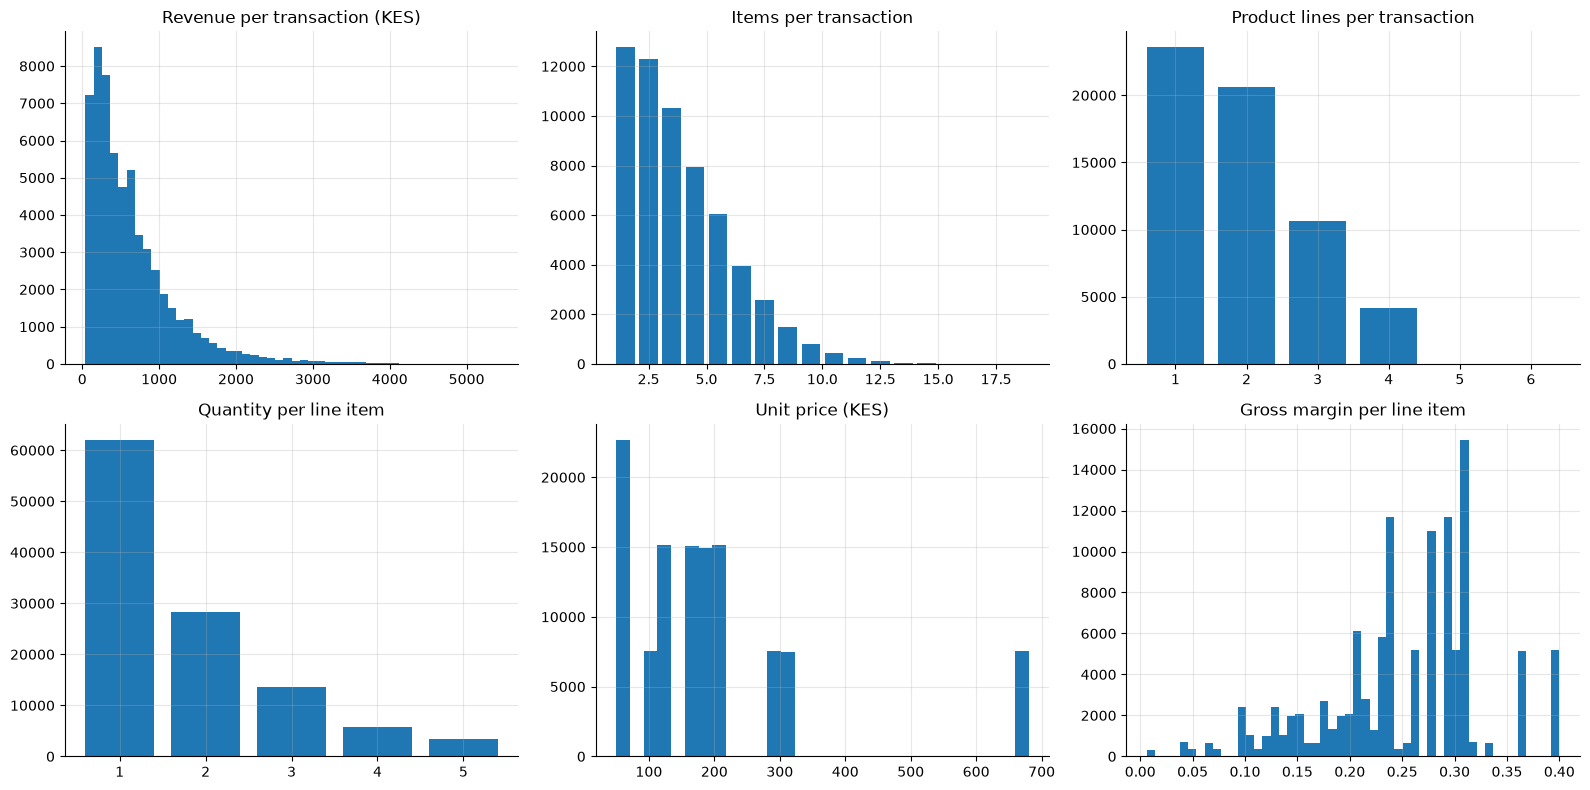

       revenue   profit    items    lines
count  58932.0  58932.0  58932.0  58932.0
mean     636.9    153.1      3.4      1.9
std      572.1    139.1      2.2      0.9
min       40.0      1.0      1.0      1.0
25%      234.0     54.0      2.0      1.0
50%      477.0    110.0      3.0      2.0
75%      844.8    205.0      5.0      3.0
max     5405.0   1345.0     17.0      4.0
skewness of revenue per transaction: 2.09
            count   mean    std   min    25%    50%    75%     max
is_guest                                                          
False     56002.0  636.4  571.7  40.0  234.0  477.0  841.5  5405.0
True       2930.0  645.7  581.2  40.0  225.0  480.0  870.0  5140.0


In [4]:
### Distribution for Numeric variables
txn = df.groupby(TXN).agg(revenue=(REV, "sum"), profit=(PROFIT, "sum"),
                          items=(QTY, "sum"), lines=(TXN, "size"),
                          is_guest=("is_guest", "first"))

fig, ax = plt.subplots(2, 3, figsize=(16, 8))
ax[0,0].hist(txn["revenue"], bins=50);              ax[0,0].set_title("Revenue per transaction (KES)")
ax[0,1].hist(txn["items"], bins=range(1, 20), rwidth=0.8); ax[0,1].set_title("Items per transaction")
ax[0,2].hist(txn["lines"], bins=range(1, 8), align="left", rwidth=0.8); ax[0,2].set_title("Product lines per transaction")
ax[1,0].hist(df[QTY], bins=range(1, 7), align="left", rwidth=0.8); ax[1,0].set_title("Quantity per line item")
ax[1,1].hist(df["unit_price_kes"], bins=30);        ax[1,1].set_title("Unit price (KES)")
ax[1,2].hist((df[PROFIT] / df[REV]).dropna(), bins=50); ax[1,2].set_title("Gross margin per line item")
save("01a_numeric_distributions")

print(txn[["revenue", "profit", "items", "lines"]].describe().round(1))
print("skewness of revenue per transaction:", round(txn["revenue"].skew(), 2))
print(txn.groupby("is_guest")["revenue"].describe().round(1))

**Observations:**
The typical transaction is small. Mean revenue is about KES 637 and the median about KES 477, with 1 to 4 product lines and about 3 items.
Revenue per transaction is right-skewed (skewness 2.09), so a minority of large baskets pulls the mean above the median. 
Guest and known-customer baskets are almost the same size, so guests are not a different kind of shopper.

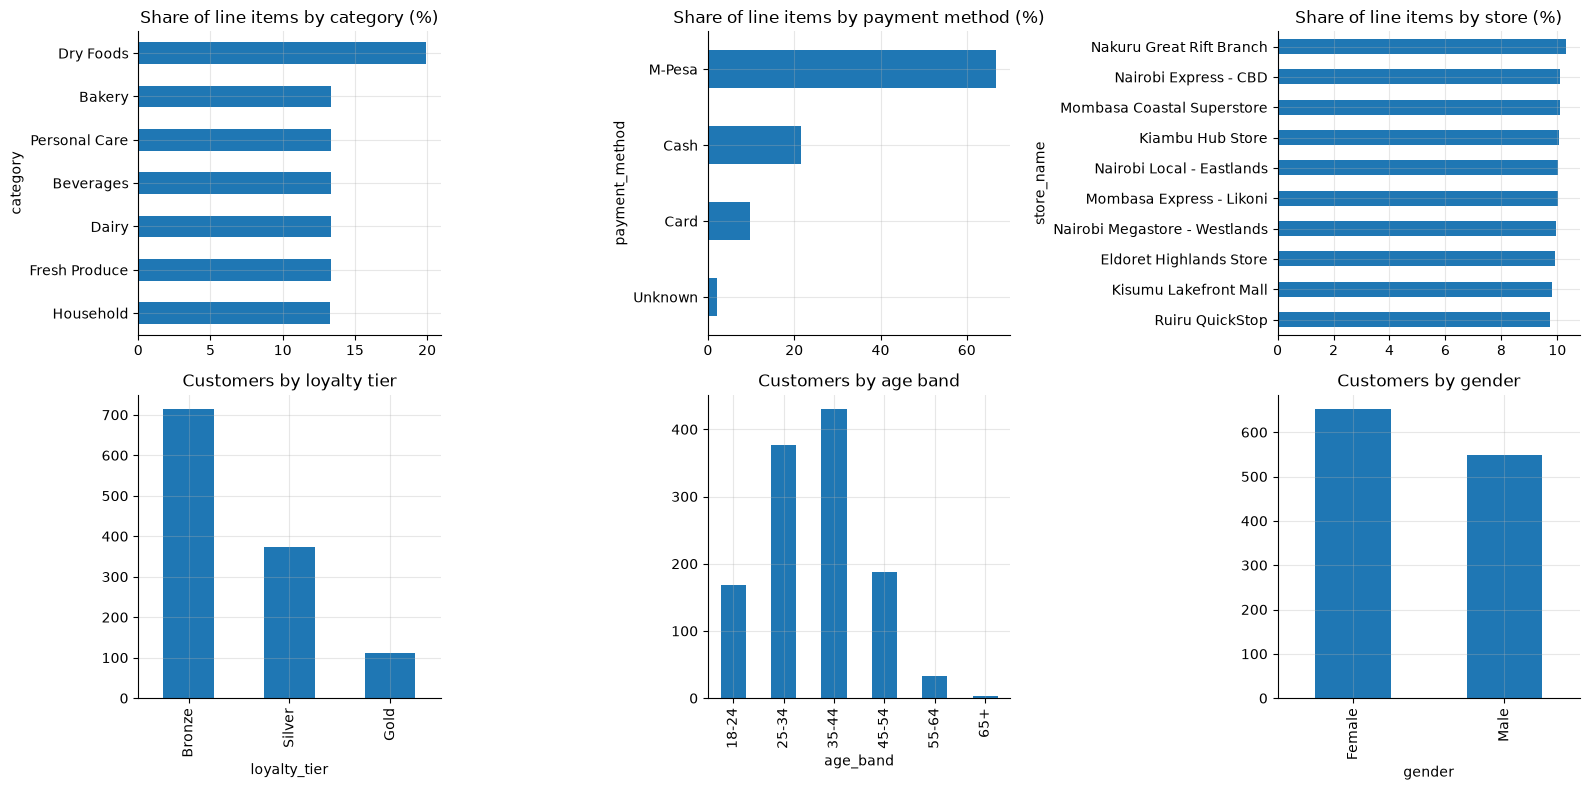

count    1200.0
mean       35.6
std         9.6
min        18.0
25%        29.0
50%        36.0
75%        42.0
max        67.0
Name: age, dtype: float64
is_guest
False    0.949
True     0.051
Name: proportion, dtype: float64


In [5]:
### Distribution for Categoric Variables 

fig, ax = plt.subplots(2, 3, figsize=(16, 8))

(df[CAT].value_counts(normalize=True) * 100).sort_values().plot.barh(ax=ax[0,0], title="Share of line items by category (%)")
(df[PAY].value_counts(normalize=True) * 100).sort_values().plot.barh(ax=ax[0,1], title="Share of line items by payment method (%)")
(df[STORE].value_counts(normalize=True) * 100).sort_values().plot.barh(ax=ax[0,2], title="Share of line items by store (%)")

cust = customers.copy()
cust["age_band"] = pd.cut(cust["age"], [17, 24, 34, 44, 54, 64, 120],
                          labels=["18-24","25-34","35-44","45-54","55-64","65+"])
cust["loyalty_tier"].value_counts().plot.bar(ax=ax[1,0], title="Customers by loyalty tier")
cust["age_band"].value_counts().sort_index().plot.bar(ax=ax[1,1], title="Customers by age band")
cust["gender"].value_counts().plot.bar(ax=ax[1,2], title="Customers by gender")
save("01b_categorical_distributions")

print(cust["age"].describe().round(1))
print(df["is_guest"].value_counts(normalize=True).round(3))

**Observation** 

The customer base is young and mostly Bronze: the median age is 36, most customers are between 25 and 44, and the 55+ groups are very small.
About 5% of transactions are guests with no customer ID. The line-item shares by category, payment method, and store are distribution checks only. 

In [6]:
### Distribution of demand across the 15 products, is it evenly?

prod_share = (df["product_id"].value_counts(normalize=True) * 100).round(1).sort_index()
print(prod_share)
print("range of product share of line items: %.1f%% to %.1f%%" % (prod_share.min(), prod_share.max()))
print(df.groupby("is_guest")["transaction_id"].nunique())

product_id
PRD_001    6.7
PRD_002    6.6
PRD_003    6.7
PRD_004    6.7
PRD_005    6.7
PRD_006    6.7
PRD_007    6.7
PRD_008    6.7
PRD_009    6.7
PRD_010    6.7
PRD_011    6.7
PRD_012    6.6
PRD_013    6.6
PRD_014    6.7
PRD_015    6.7
Name: proportion, dtype: float64
range of product share of line items: 6.6% to 6.7%
is_guest
False    56002
True      2930
Name: transaction_id, dtype: int64


**Observations:** 
Every product accounts for 6.6% to 6.7% of line items, which is exactly one-fifteenth.
Real shoppers do not buy every product equally, so this is a sign of how the data was generated. It means product popularity in the sales file carries no signal. 

## Trends 
This section shows how revenue, margin, and transactions move month by month, whether 2026 is growing against 2025, and what happens in the months with promotions.

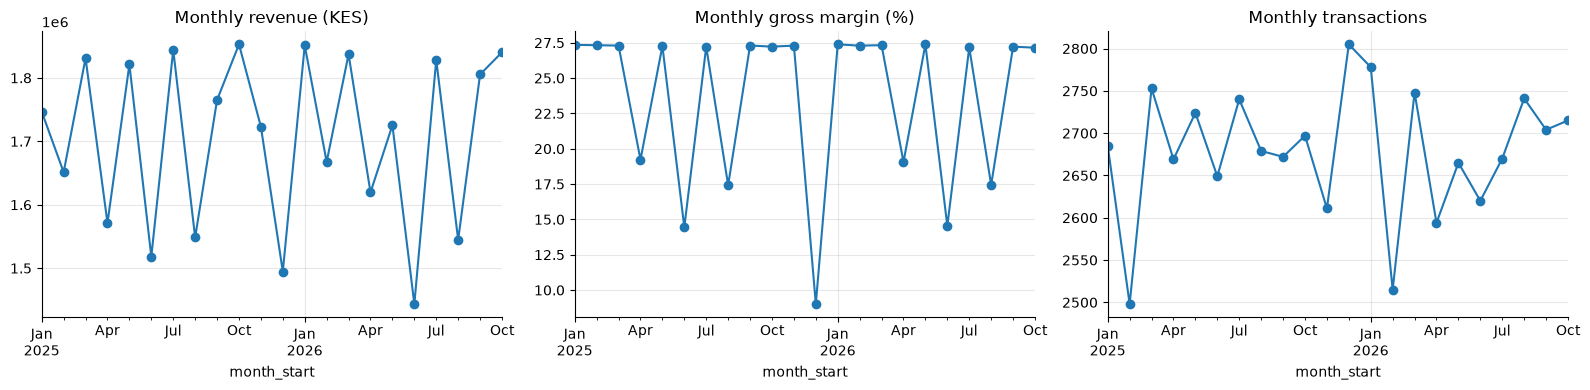

In [7]:
monthly = df.groupby("month_start").agg(revenue=(REV, "sum"), profit=(PROFIT, "sum"),
                                         transactions=(TXN, "nunique"))
monthly["margin_pct"] = monthly["profit"] / monthly["revenue"] * 100

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
monthly["revenue"].plot(ax=ax[0], marker="o", title="Monthly revenue (KES)")
monthly["margin_pct"].plot(ax=ax[1], marker="o", title="Monthly gross margin (%)")
monthly["transactions"].plot(ax=ax[2], marker="o", title="Monthly transactions")
save("04a_monthly_trend")

year        2025       2026  growth_pct
month                                  
1      1746825.0  1851255.0         6.0
2      1651310.0  1667540.0         1.0
3      1831210.0  1837235.0         0.3
4      1571058.0  1619518.5         3.1
5      1821190.0  1725305.0        -5.3
6      1518197.8  1443440.2        -4.9
7      1844105.0  1828465.0        -0.8
8      1548390.8  1544549.6        -0.2
9      1765160.0  1805405.0         2.3
10     1852945.0  1840445.0        -0.7
Jan to Oct total growth: 0.1%


Text(0.5, 0, 'month')

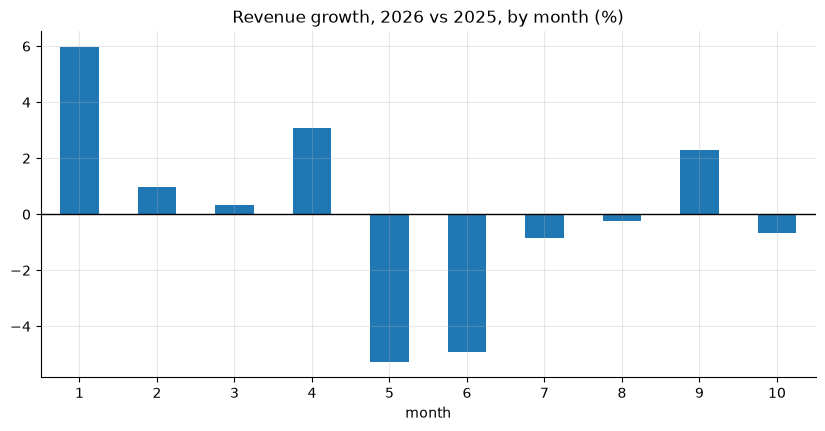

In [8]:
### Trend - Year on year, January to October same months only

sub = df[df[DATE].dt.month <= 10]
yoy = (sub.groupby([sub[DATE].dt.year.rename("year"), sub[DATE].dt.month.rename("month")])[REV]
          .sum().unstack("year"))
yoy["growth_pct"] = (yoy[2026] / yoy[2025] - 1) * 100
print(yoy.round(1))
total_growth = (yoy[2026].sum() / yoy[2025].sum() - 1) * 100
print("Jan to Oct total growth: %.1f%%" % total_growth)

ax = yoy["growth_pct"].plot.bar(rot=0, title="Revenue growth, 2026 vs 2025, by month (%)")
ax.axhline(0, color="black", lw=1); ax.set_xlabel("month")

**Observation** 

Revenue is flat. January to October 2026 is only 0.1% above the same months of 2025, and monthly growth swings between -5.3% and +6.0% with no sustained direction. Transactions stay in a narrow band of roughly 2,500 to 2,800 a month.

               gross        net  discount    profit  transactions  discount_pct_of_gross  margin_pct                        promo
month_start                                                                                                                      
2025-01-01   1746825  1746825.0       0.0  477740.0          2685                    0.0        27.3                          NaN
2025-02-01   1651310  1651310.0       0.0  451237.0          2498                    0.0        27.3                          NaN
2025-03-01   1831210  1831210.0       0.0  499877.0          2753                    0.0        27.3                          NaN
2025-04-01   1745620  1571058.0  174562.0  302041.0          2669                   10.0        19.2    Easter Super Savings 2025
2025-05-01   1821190  1821190.0       0.0  496579.0          2724                    0.0        27.3                          NaN
2025-06-01   1786115  1518197.8  267917.2  219346.8          2649                   15.0  

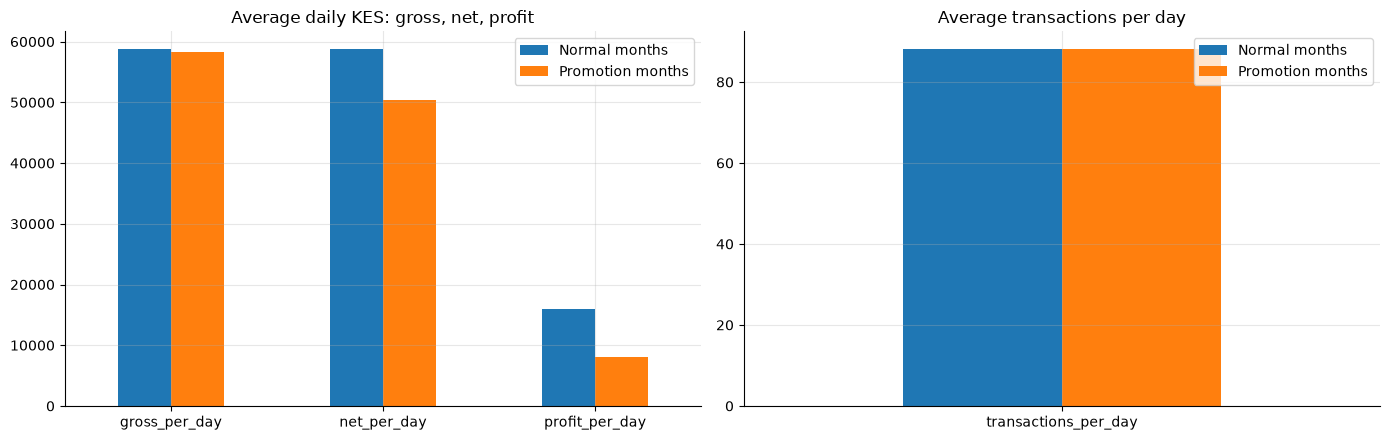

In [9]:
### Promotion months: discounts, margin, and volume.

m2 = df.groupby("month_start").agg(gross=("gross_sales_kes", "sum"), net=(REV, "sum"),
                                    discount=("discount_amount_kes", "sum"), profit=(PROFIT, "sum"),
                                    transactions=(TXN, "nunique"))
m2["discount_pct_of_gross"] = m2["discount"] / m2["gross"] * 100
m2["margin_pct"] = m2["profit"] / m2["net"] * 100
m2["is_promo"] = m2["discount"] > 0
m2["promo"] = (df[df["promo_id"] != "PROMO_NONE"].groupby("month_start")["promo_name"].first())
print(m2[["gross", "net", "discount", "profit", "transactions",
          "discount_pct_of_gross", "margin_pct", "promo"]].round(1).to_string())

# Compare promotion months with normal months using per-day averages (months differ in length)
m2["days"] = m2.index.days_in_month
for c in ["gross", "net", "profit", "transactions"]:
    m2[c + "_per_day"] = m2[c] / m2["days"]
lift = m2.groupby("is_promo")[["gross_per_day", "net_per_day", "profit_per_day",
                               "transactions_per_day", "margin_pct"]].mean().round(1)
lift.index = ["Normal months", "Promotion months"]
lift.loc["Promo vs normal (%)"] = ((lift.loc["Promotion months"] / lift.loc["Normal months"] - 1) * 100).round(1)
print(lift)
print(promotions)

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
lift.iloc[:2][["gross_per_day", "net_per_day", "profit_per_day"]].T.plot.bar(ax=ax[0], rot=0,
        title="Average daily KES: gross, net, profit")
lift.iloc[:2][["transactions_per_day"]].T.plot.bar(ax=ax[1], rot=0, title="Average transactions per day")
save("04c_promotion_months")

**Observations** 

Promotion months carry discounts of 10% to 20% of gross sales and margin falls from about 27% to between 9% and 19%. Gross sales per day (the sales before discount) and transactions per day in promotion months are no higher than in normal months, so the discounts do not appear to bring in extra volume. 

## Seasonality
This asks how sales change by day of week, week of the month, month, and around public holidays. 

days: 669 | days with no sales: 0
           avg_daily_revenue  avg_transactions  index_vs_avg
dow                                                         
Monday               57172.2              91.4         101.9
Tuesday              69494.1             109.1         123.9
Wednesday            63985.6              99.3         114.1
Thursday             50618.7              78.7          90.2
Friday               50415.5              78.7          89.9
Saturday             51471.8              80.3          91.7
Sunday               49628.2              79.3          88.5
               avg_daily_revenue  index_vs_avg
week_of_month                                 
1                        56071.2          99.9
2                        55982.9          99.8
3                        56333.6         100.4
4                        56629.4         100.9
5                        54311.9          96.8
year      2025     2026
month                  
1      56349.0  59718.0
2      58975.0  

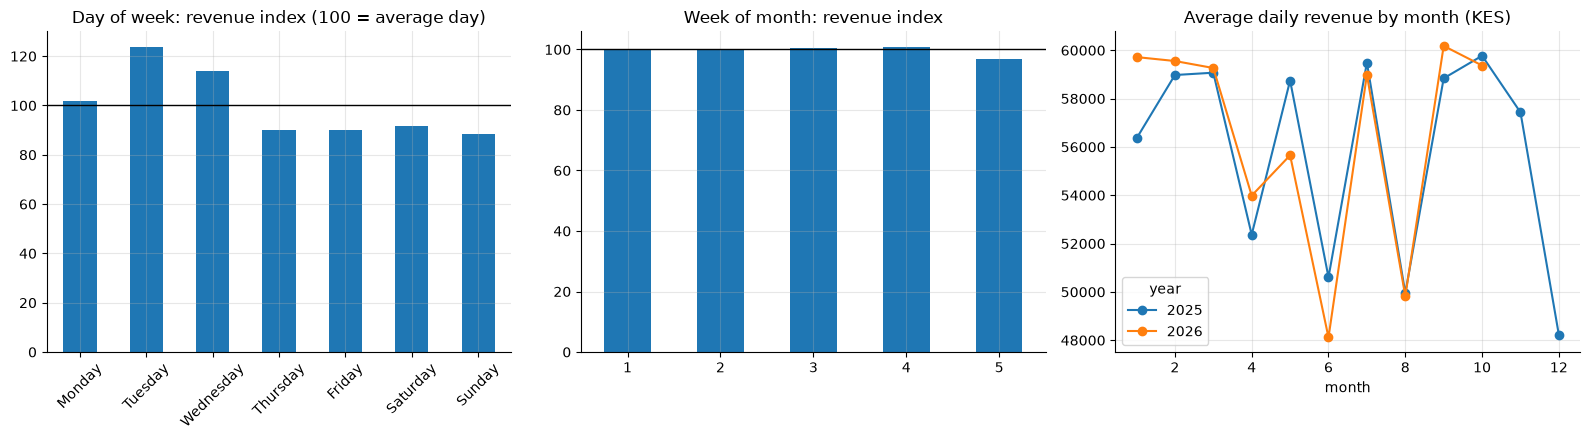

In [10]:
### Day of week, week of month, and month

daily = df.groupby(DATE).agg(revenue=(REV, "sum"), transactions=(TXN, "nunique"))
daily = daily.reindex(pd.date_range(df[DATE].min(), df[DATE].max(), freq="D"), fill_value=0)
daily.index.name = "date"
print("days:", len(daily), "| days with no sales:", (daily["revenue"] == 0).sum())

daily["dow"]           = daily.index.day_name()
daily["month"]         = daily.index.month
daily["year"]          = daily.index.year
daily["week_of_month"] = (daily.index.day - 1) // 7 + 1      # 1 = days 1-7 ... 5 = days 29-31
daily["is_holiday"]    = daily.index.isin(holidays["Date"])

overall = daily["revenue"].mean()
order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]

dow = daily.groupby("dow").agg(avg_daily_revenue=("revenue", "mean"),
                               avg_transactions=("transactions", "mean")).reindex(order)
dow["index_vs_avg"] = dow["avg_daily_revenue"] / overall * 100
print(dow.round(1))

wom = daily.groupby("week_of_month").agg(avg_daily_revenue=("revenue", "mean"))
wom["index_vs_avg"] = wom["avg_daily_revenue"] / overall * 100
print(wom.round(1))

# Average DAILY revenue per month (fair across 28 to 31 day months), one column per year
mon = daily.groupby(["year", "month"])["revenue"].mean().unstack("year")
print(mon.round(0))

fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
dow["index_vs_avg"].plot.bar(ax=ax[0], rot=45, title="Day of week: revenue index (100 = average day)")
wom["index_vs_avg"].plot.bar(ax=ax[1], rot=0, title="Week of month: revenue index")
mon[[2025, 2026]].plot(ax=ax[2], marker="o", title="Average daily revenue by month (KES)")
for a in ax[:2]:
    a.axhline(100, color="black", lw=1)
    a.set_xlabel("")
save("05a_calendar_patterns")

**Observations** 

The strongest pattern is the day of the week. Tuesday is the busiest day (index 124, about 109 transactions) and Wednesday is next (114), Monday is average (102), and Thursday to Sunday are all 8% to 12% below average (88 to 92). Weekends are not busier than weekdays. The week of the month makes almost no difference (indices 97 to 101), so there is no sign of a month-end pay effect. 
The monthly lines for 2025 and 2026 move together: the low months (April, June, August, December) are the promotion months, because this chart uses net revenue and the discounts pull it down. Outside promotion months, average daily revenue stays between about KES 56,000 and 60,000 with no clear seasonal peak.

holidays inside the sales period: 22
                              holiday        dow   revenue  transactions   rel
date                                                                          
2025-01-01             New Year's Day  Wednesday  76610.00           124  1.09
2025-03-31              Eid al-Fitr *     Monday  50920.00            89  0.94
2025-04-18                Good Friday     Friday  46440.00            77  1.09
2025-04-21              Easter Monday     Monday  48586.50            85  0.99
2025-05-01                 Labour Day   Thursday  59415.00            89  1.05
2025-06-02  Madaraka Day Substitute H     Monday  48586.00            85  1.17
2025-06-06              Eid al-Adha *     Friday  57736.25            90  1.19
2025-10-10              Mazingira Day     Friday  49780.00            84  0.90
2025-10-17  Public Mourning — State F     Friday  60755.00            85  1.10
2025-10-20                  Diwali **     Monday  58865.00            91  0.98
2025-12-12     

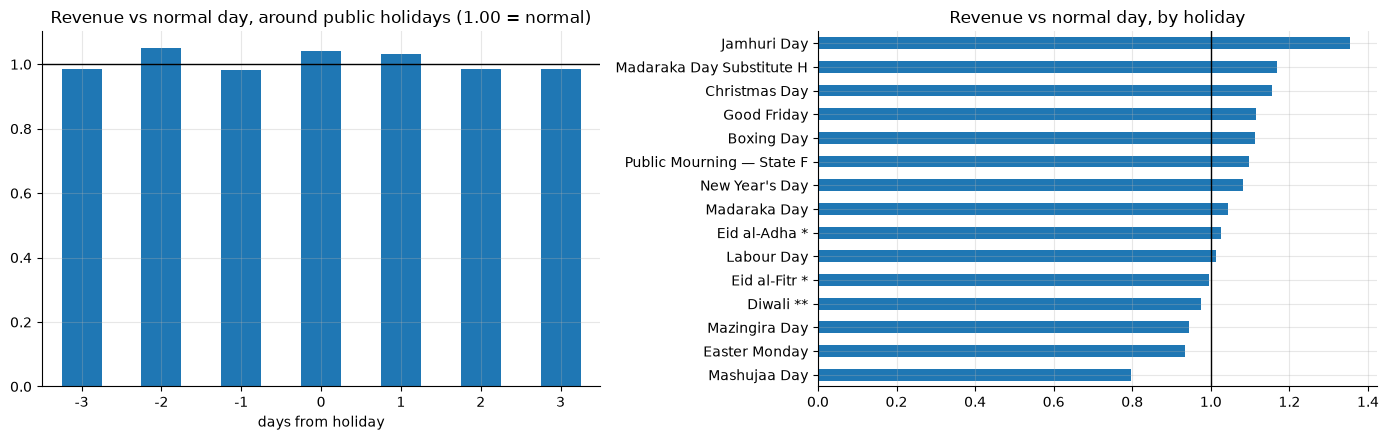

In [11]:
### Public holidays
# Compare each holiday with a fair baseline: the average NON-holiday day of the SAME weekday in the SAME month.
# This removes the weekday effect (Fridays are weak days) and the monthly promotion effect.
base = daily[~daily["is_holiday"]].groupby(["year", "month", "dow"])["revenue"].mean().rename("baseline")
daily = daily.join(base, on=["year", "month", "dow"])
daily["rel"] = daily["revenue"] / daily["baseline"]          # 1.00 = a normal day of that weekday and month

hol_names = holidays.drop_duplicates("Date").set_index("Date")["Holiday_Name"]
hol_days = daily[daily["is_holiday"]].copy()
hol_days["holiday"] = hol_names.reindex(hol_days.index)

print("holidays inside the sales period:", len(hol_days))
print(hol_days[["holiday", "dow", "revenue", "transactions", "rel"]].round(2).to_string())
print("\nAverage holiday vs normal day: %.1f%%" % ((hol_days["rel"].mean() - 1) * 100))
print("Holidays above a normal day:", (hol_days["rel"] > 1).sum(), "of", len(hol_days))

# Event window: 3 days before to 3 days after each holiday
win = {}
for off in range(-3, 4):
    idx = hol_days.index + pd.Timedelta(days=off)
    idx = idx[idx.isin(daily.index)]
    win[off] = daily.loc[idx, "rel"].mean()
win = pd.Series(win)
print(win.round(3))

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
win.plot.bar(ax=ax[0], rot=0, title="Revenue vs normal day, around public holidays (1.00 = normal)")
ax[0].axhline(1, color="black", lw=1); ax[0].set_xlabel("days from holiday")
hol_days.groupby("holiday")["rel"].mean().sort_values().plot.barh(ax=ax[1], title="Revenue vs normal day, by holiday")
ax[1].axvline(1, color="black", lw=1); ax[1].set_ylabel("")
save("05b_holiday_effect")

**Observations** 

Public holidays give only a small lift. Compared with a normal day of the same weekday in the same month, the average holiday is 4.2% higher, and 13 of the 22 holidays in the period beat a normal day. Results are mixed: Jamhuri Day 2025 (+35%), Eid al-Adha 2025 (+19%), and Madaraka Day 2025 (+17%) are high, while Mashujaa Day 2026 (-20%) and Eid al-Adha 2026 (-14%) are low. The three days before and after a holiday are within about 5% of normal, so there is no build-up or after-effect. Action: holidays alone are a weak reason to add stock; the day-of-week pattern in 5.1 matters more. With only 22 holidays, one or two days can swing the average.

months compared: 21
correlation, gross sales per day vs 12-month inflation: -0.24


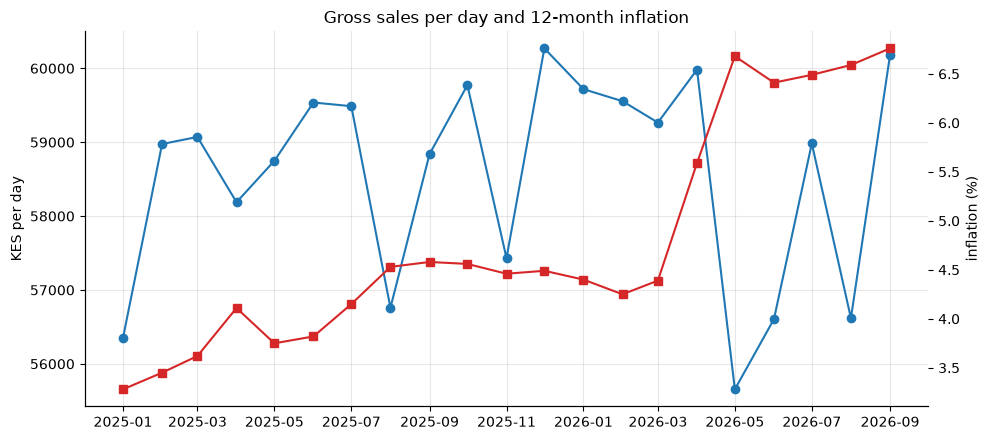

In [12]:
### Inflation and demand

infl = df.groupby("month_start").agg(gross=("gross_sales_kes", "sum"), net=(REV, "sum"),
                                      inflation_12m=("inflation_12m", "first"))
infl["days"] = infl.index.days_in_month
infl["gross_per_day"] = infl["gross"] / infl["days"]
infl = infl.dropna(subset=["inflation_12m"])          # October 2026 has no inflation value
print("months compared:", len(infl))
print("correlation, gross sales per day vs 12-month inflation: %.2f" % infl["gross_per_day"].corr(infl["inflation_12m"]))

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(infl.index, infl["gross_per_day"], marker="o", label="Gross sales per day (KES)")
ax.set_ylabel("KES per day")
ax2 = ax.twinx(); ax2.grid(False)
ax2.plot(infl.index, infl["inflation_12m"], color="tab:red", marker="s", label="12-month inflation (%)")
ax2.set_ylabel("inflation (%)")
ax.set_title("Gross sales per day and 12-month inflation")
save("05c_inflation_vs_sales")

**Observatins** 
Gross sales per day have a weak negative correlation with 12-month inflation (-0.24) over the 21 months with inflation data, and the chart shows no matching movement. Inflation only ranges between about 3% and 7% in this period, and with 21 points the correlation is not strong enough to claim an effect. 

## Segments
Here revenue and profit are split by customer group, store, county, product, and payment method. Every table reports shares, so groups of different size can be compared.


--- loyalty_tier ---
                 revenue     profit  transactions  buyers  revenue_share_%  \
loyalty_tier                                                                 
Bronze        21311103.5  5128668.5         33429   714.0             56.8   
Silver        11078944.4  2660857.4         17441   374.0             29.5   
Gold           3249296.1   777920.1          5132   112.0              8.7   
Guest          1891812.8   454861.8          2930     NaN              5.0   

              txn_share_%  avg_basket_kes  margin_%  rev_per_buyer  
loyalty_tier                                                        
Bronze               56.7           637.5      24.1        29847.5  
Silver               29.6           635.2      24.0        29622.8  
Gold                  8.7           633.1      23.9        29011.6  
Guest                 5.0           645.7      24.0            NaN  

--- age_band ---
             revenue     profit  transactions  buyers  revenue_share_%  \
age

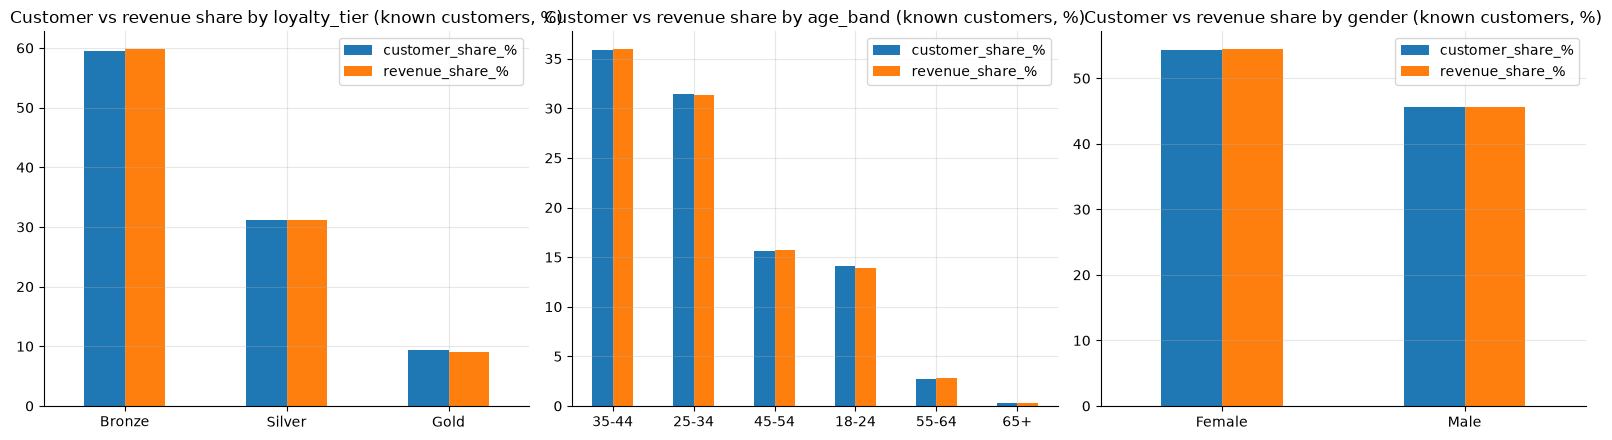

In [13]:
### Customer segments 

def segment_table(col):
    t = df.groupby(col).agg(revenue=(REV, "sum"), profit=(PROFIT, "sum"),
                            transactions=(TXN, "nunique"),
                            buyers=("customer_id", "nunique"))
    t["revenue_share_%"] = t["revenue"] / t["revenue"].sum() * 100
    t["txn_share_%"]     = t["transactions"] / t["transactions"].sum() * 100
    t["avg_basket_kes"]  = t["revenue"] / t["transactions"]
    t["margin_%"]        = t["profit"] / t["revenue"] * 100
    t["rev_per_buyer"]   = t["revenue"] / t["buyers"]
    if "Guest" in t.index:                      # guests are not one person
        t.loc["Guest", ["buyers", "rev_per_buyer"]] = np.nan
    return t.sort_values("revenue", ascending=False).round(1)

for col in ["loyalty_tier", "age_band", "gender"]:
    print(f"\n--- {col} ---")
    print(segment_table(col))

fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
for a, col in zip(ax, ["loyalty_tier", "age_band", "gender"]):
    t = segment_table(col).drop(index="Guest")
    t["customer_share_%"] = t["buyers"] / t["buyers"].sum() * 100
    t["revenue_share_%"]  = t["revenue"] / t["revenue"].sum() * 100
    t[["customer_share_%", "revenue_share_%"]].plot.bar(ax=a, rot=0)
    a.set_title(f"Customer vs revenue share by {col} (known customers, %)")
    a.set_xlabel("")
save("06a_segment_shares")

**Findings**
Bronze customers, 35-44-year-olds, and women generate the most revenue and transactions, but only because they are the largest groups. 
Bronze is 56.8% of revenue (KES 21.3M), the 35-44 band is 34.1%, and women are 51.7%. 
Revenue per buyer (about KES 29,000 to 31,000), average basket (about KES 635), and margin (about 24%) are almost identical across tiers, age bands, and genders. Gold customers do not spend more than Bronze (KES 29,012 against KES 29,848 per buyer), so the loyalty tiers do not currently track spending. The 55-64 and 65+ bands have only 33 and 3 buyers, so their slightly higher baskets are not interpreted.

                   store_name store_format store_county  sqft   revenue   profit  transactions  revenue_share_%  avg_basket_kes  margin_%  rev_per_sqft_per_month
     Nakuru Great Rift Branch  Supermarket       Nakuru 10000 3871651.5 925418.5          6051             10.3           639.8      23.9                    17.6
             Kiambu Hub Store  Supermarket       Kiambu 12000 3823135.4 916027.4          5885             10.2           649.6      24.0                    14.5
     Mombasa Express - Likoni  Supermarket      Mombasa  7500 3806929.6 912603.6          5891             10.1           646.2      24.0                    23.1
   Mombasa Coastal Superstore  Hypermarket      Mombasa 20000 3797074.9 917648.9          5913             10.1           642.2      24.2                     8.6
        Nairobi Express - CBD  Supermarket      Nairobi  8500 3792841.3 911617.3          5954             10.1           637.0      24.0                    20.3
    Nairobi Local - Eastland

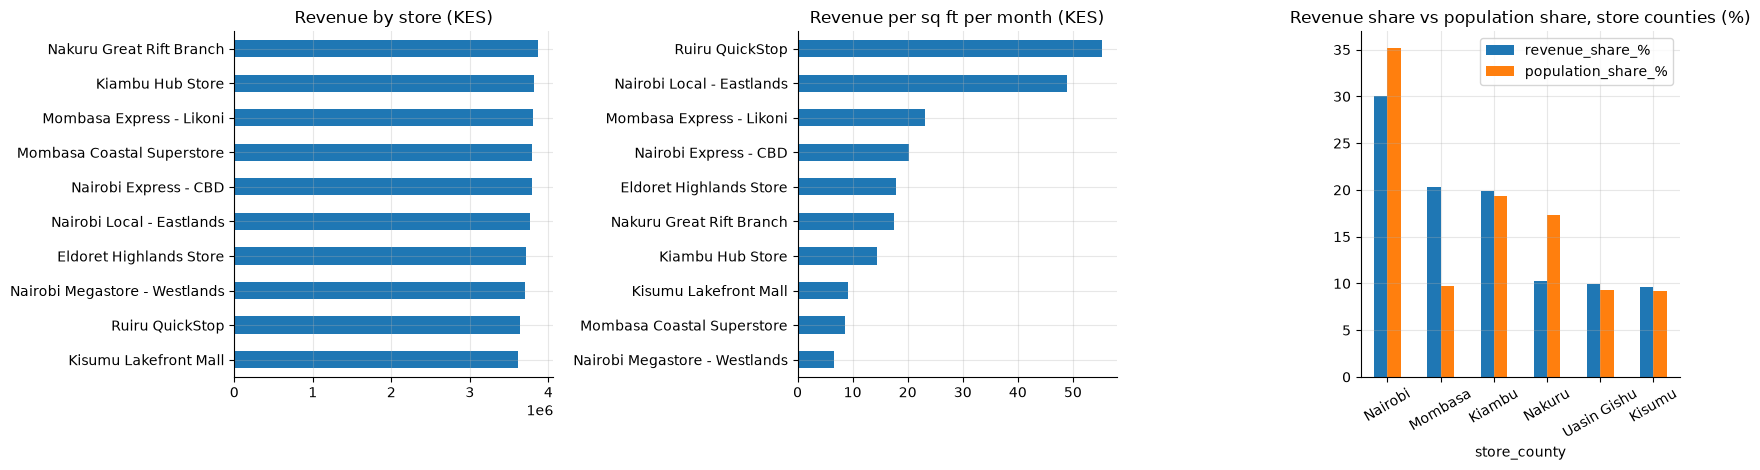

In [14]:
### Stores, formats, and counties 

months = df[DATE].dt.to_period("M").nunique()

store_t = (df.groupby(["store_name", "store_format", "store_county", "sqft"])
             .agg(revenue=(REV, "sum"), profit=(PROFIT, "sum"), transactions=(TXN, "nunique"))
             .reset_index())
store_t["revenue_share_%"]        = store_t["revenue"] / store_t["revenue"].sum() * 100
store_t["avg_basket_kes"]         = store_t["revenue"] / store_t["transactions"]
store_t["margin_%"]               = store_t["profit"] / store_t["revenue"] * 100
store_t["rev_per_sqft_per_month"] = store_t["revenue"] / store_t["sqft"] / months
store_t = store_t.sort_values("revenue", ascending=False).round(1)
print(store_t.to_string(index=False))

fmt_t = (store_t.groupby("store_format")
               .agg(stores=("store_name", "size"), revenue=("revenue", "sum"), sqft=("sqft", "sum")))
fmt_t["revenue_share_%"]        = fmt_t["revenue"] / fmt_t["revenue"].sum() * 100
fmt_t["rev_per_sqft_per_month"] = fmt_t["revenue"] / fmt_t["sqft"] / months
print(fmt_t.round(1))

county_t = df.groupby(COUNTY).agg(revenue=(REV, "sum"), transactions=(TXN, "nunique"),
                                  stores=("store_id", "nunique"),
                                  population=("county_population", "first"))
county_t["revenue_share_%"]    = county_t["revenue"] / county_t["revenue"].sum() * 100
county_t["population_share_%"] = county_t["population"] / county_t["population"].sum() * 100
county_t["revenue_per_1000_residents"] = county_t["revenue"] / county_t["population"] * 1000
county_t = county_t.sort_values("revenue", ascending=False).round(1)
print(county_t)

fig, ax = plt.subplots(1, 3, figsize=(17, 4.8))
rev_by_store = store_t.set_index("store_name")["revenue"].sort_values()
rev_by_store.plot.barh(ax=ax[0], title="Revenue by store (KES)")
store_t.set_index("store_name")["rev_per_sqft_per_month"].sort_values().plot.barh(ax=ax[1], title="Revenue per sq ft per month (KES)")
county_t[["revenue_share_%", "population_share_%"]].plot.bar(ax=ax[2], rot=30, title="Revenue share vs population share, store counties (%)")
for a in ax: a.set_ylabel("")
save("06b_stores_counties")

**Findings**

Total revenue is almost the same in every store, between 9.6% and 10.3% of the chain total (KES 3.6M to 3.9M each), regardless of size. Nakuru, Kiambu Hub, and Mombasa Likoni lead, and Kisumu Lakefront is last, but the gap between first and last is only about 7%. 
Because the stores are so different in size, revenue per square foot varies enormously: the small Ruiru QuickStop (KES 55 per sq ft per month) and Nairobi Eastlands (49) earn about five to eight times more per square foot than the hypermarkets (7 to 9 for Westlands, Mombasa Coastal, and Kisumu). By format, the six supermarkets bring in 60.7% of revenue, the three hypermarkets 29.6%, and the single convenience store 9.7%. By county, Nairobi has the largest revenue share (30.0%) but is below its population share (35.2%); Mombasa earns the most per 1,000 residents (KES 6,293) and Nakuru the least (KES 1,791). Counties with two or three stores will naturally earn more, and customers do not necessarily live in the store's county, so per-resident figures are a rough guide. 

                  revenue     profit  units  revenue_share_%  margin_%
category                                                              
Dry Foods      13837892.4  2712317.4  39749             36.9      19.6
Household       6446635.0  1645005.0  26691             17.2      25.5
Beverages       5401097.0  1374497.0  26712             14.4      25.4
Personal Care   4570637.2  1253337.2  26494             12.2      27.4
Fresh Produce   3447077.9  1046767.9  26681              9.2      30.4
Dairy           2361009.8   588715.8  26589              6.3      24.9
Bakery          1466807.6   401667.6  26650              3.9      27.4
                  product_name      category  unit_price_kes   revenue    profit  units  revenue_share_%  margin_%
          Pwani Cooking Oil 3L     Dry Foods             680 8736055.2 1757135.2  13421             23.3      20.1
        Omo Washing Powder 1kg     Household             320 4076812.8 1013672.8  13318             10.9      24.9
    Kericho Gold

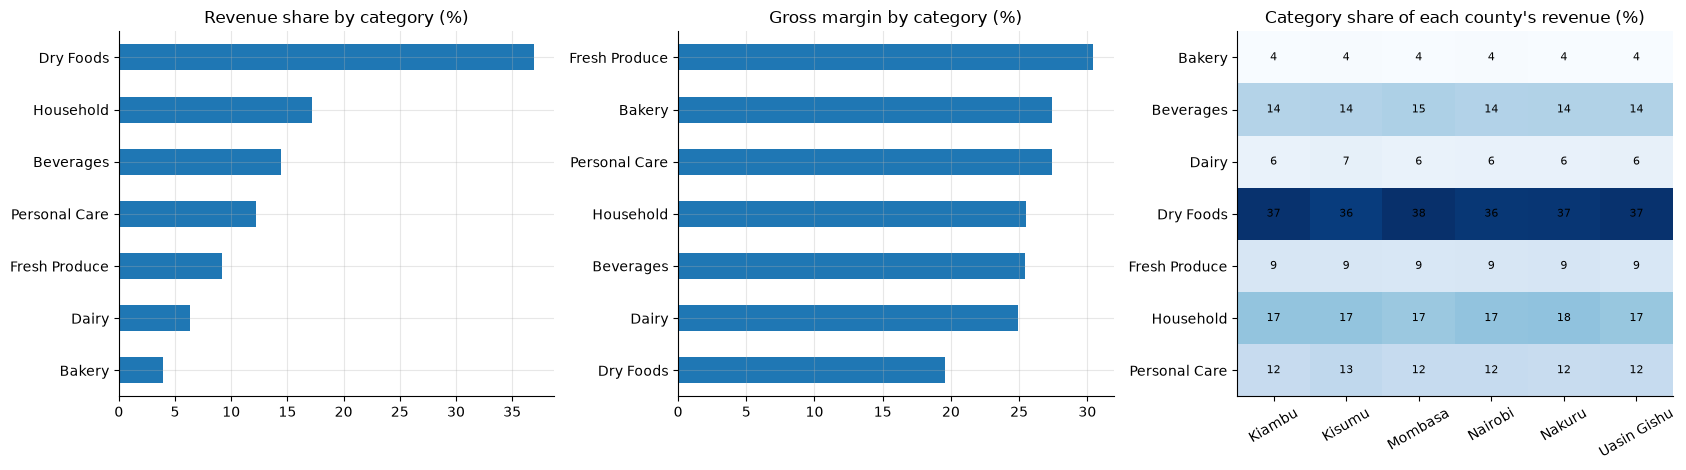

In [15]:
 ### Categories and products

cat_t = df.groupby(CAT).agg(revenue=(REV, "sum"), profit=(PROFIT, "sum"), units=(QTY, "sum"))
cat_t["revenue_share_%"] = cat_t["revenue"] / cat_t["revenue"].sum() * 100
cat_t["margin_%"]        = cat_t["profit"] / cat_t["revenue"] * 100
cat_t = cat_t.sort_values("revenue", ascending=False).round(1)
print(cat_t)

prod_t = (df.groupby(["product_name", CAT, "unit_price_kes"])
            .agg(revenue=(REV, "sum"), profit=(PROFIT, "sum"), units=(QTY, "sum")).reset_index())
prod_t["revenue_share_%"] = prod_t["revenue"] / prod_t["revenue"].sum() * 100
prod_t["margin_%"]        = prod_t["profit"] / prod_t["revenue"] * 100
prod_t = prod_t.sort_values("revenue", ascending=False).round(1)
print(prod_t.to_string(index=False))

#  weakest products, bottom 20% by revenue (3 of 15)
print("\nBottom 20% of products by revenue:", prod_t.tail(3)["product_name"].tolist())

# category revenue by county, each county's revenue = 100%
cc = df.pivot_table(index=CAT, columns=COUNTY, values=REV, aggfunc="sum")
cc_share = cc / cc.sum() * 100
print(cc_share.round(1))

fig, ax = plt.subplots(1, 3, figsize=(17, 4.8))
cat_t["revenue_share_%"].sort_values().plot.barh(ax=ax[0], title="Revenue share by category (%)")
cat_t["margin_%"].sort_values().plot.barh(ax=ax[1], title="Gross margin by category (%)")
im = ax[2].imshow(cc_share.values, aspect="auto", cmap="Blues")
ax[2].set_xticks(range(len(cc_share.columns))); ax[2].set_xticklabels(cc_share.columns, rotation=30)
ax[2].set_yticks(range(len(cc_share.index))); ax[2].set_yticklabels(cc_share.index)
ax[2].set_title("Category share of each county's revenue (%)"); ax[2].grid(False)
for i in range(cc_share.shape[0]):
    for j in range(cc_share.shape[1]):
        ax[2].text(j, i, f"{cc_share.values[i, j]:.0f}", ha="center", va="center", fontsize=8)
for a in ax[:2]: a.set_ylabel("")
save("06c_categories_products")

**Findings**:
Dry Foods is the largest category (36.9% of revenue, KES 13.8M) but has the lowest margin (19.6%). Fresh Produce has the highest margin (30.4%) on 9.2% of revenue, and Bakery is the smallest category (3.9%). 
One product, Pwani Cooking Oil 3L, brings in 23.3% of all revenue, and the top three products (Pwani Cooking Oil, Omo Washing Powder, Kericho Gold Tea) make up 44%. Every product sells about 13,000 to 13,500 units, so revenue differences come from price. The bottom 20% of products by revenue are Festive Bread, Maziwa Fresh Milk, and Mandazi Pack, each about 2% or less; Mandazi still has the highest margin of any product (37.3%), while Pembe Wheat Flour has the lowest (16.9%). The category mix is almost identical in every county (for example, Dry Foods is 35.9% to 37.5% everywhere), so there is no county-specific demand to act on in this data. 

max payment methods per transaction: 1
         transactions_%  revenue_%
pay                               
Card                9.7        9.5
Cash               21.5       21.6
M-Pesa             66.8       66.8
Unknown             2.0        2.0
pay          Card  Cash  M-Pesa  Unknown
county                                  
Kiambu        9.5  21.1    67.3      2.2
Kisumu        9.1  21.7    67.4      1.9
Mombasa       9.6  21.1    67.4      2.0
Nairobi      10.1  21.9    66.0      2.0
Nakuru        9.9  21.2    66.7      2.2
Uasin Gishu   9.5  22.0    66.6      1.9
pay          Card  Cash  M-Pesa  Unknown
fmt                                     
Convenience   9.5  21.0    67.5      2.1
Hypermarket   9.6  21.4    66.9      2.0
Supermarket   9.7  21.6    66.7      2.0
pay           Card  Cash  M-Pesa  Unknown
basket_band                              
Small (Q1)     9.8  21.3    66.8      2.1
Medium (Q2)    9.8  21.4    66.9      1.9
Large (Q3)     9.7  21.5    66.8      2.0
Largest 

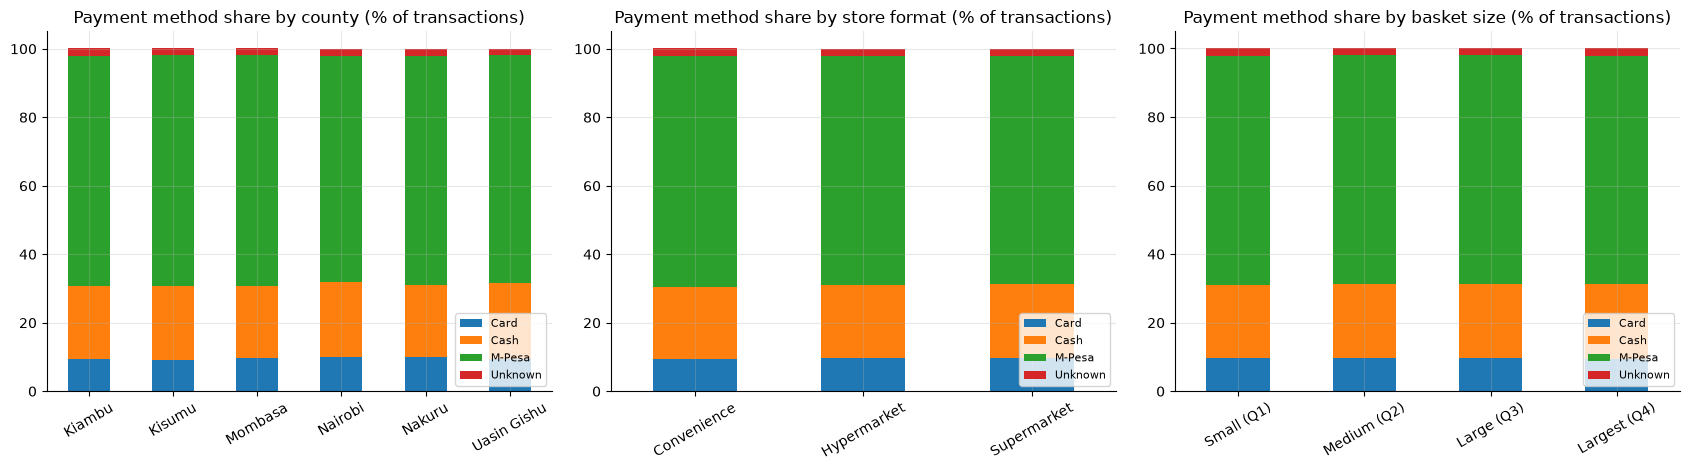

In [16]:
### Payment methods
# Each payment method per transaction.
print("max payment methods per transaction:", df.groupby(TXN)[PAY].nunique().max())

t2 = df.groupby(TXN).agg(revenue=(REV, "sum"), pay=(PAY, "first"), county=(COUNTY, "first"),
                         fmt=("store_format", "first"), store=(STORE, "first"))
t2["basket_band"] = pd.qcut(t2["revenue"], 4, labels=["Small (Q1)", "Medium (Q2)", "Large (Q3)", "Largest (Q4)"])

overall_pay = pd.DataFrame({"transactions_%": t2["pay"].value_counts(normalize=True) * 100,
                            "revenue_%": t2.groupby("pay")["revenue"].sum() / t2["revenue"].sum() * 100}).round(1)
print(overall_pay)

by_county = (pd.crosstab(t2["county"], t2["pay"], normalize="index") * 100).round(1)
by_format = (pd.crosstab(t2["fmt"],    t2["pay"], normalize="index") * 100).round(1)
by_basket = (pd.crosstab(t2["basket_band"], t2["pay"], normalize="index") * 100).round(1)
print(by_county); print(by_format); print(by_basket)

fig, ax = plt.subplots(1, 3, figsize=(17, 4.8))
for a, tab, title in zip(ax, [by_county, by_format, by_basket],
                         ["by county", "by store format", "by basket size"]):
    tab.plot.bar(stacked=True, ax=a, rot=30, title=f"Payment method share {title} (% of transactions)")
    a.set_xlabel(""); a.legend(fontsize=8, loc="lower right")
save("06d_payment_methods")

**Findings:** 
M-Pesa is the main payment method at 66.8% of transactions and revenue, followed by Cash (21.5%), Card (9.7%), and Unknown (2.0%). 
The split barely changes anywhere:
M-Pesa is between 66.0% (Nairobi) and 67.4% by county, between 66.7% and 67.5% by store format, and between 66.7% and 66.9% across the four basket-size bands. 
Payment method does not depend on county, format, or basket size in this data. 

customers in table: 1200 | with at least one purchase: 1200
       transactions    spend  recency_days
count        1200.0   1200.0        1200.0
mean           46.7  29699.5          13.9
std             6.9   5858.7          14.3
min            26.0  14673.0           0.0
25%            42.0  25478.4           4.0
50%            46.0  29328.5           9.5
75%            51.0  33542.7          20.0
max            71.0  50054.6         144.0

gap between visits (days), percentiles:
0.50    10.0
0.75    20.0
0.90    33.0
0.95    42.0
0.99    63.0
Name: transaction_date, dtype: float64
customers with no purchase in the last 30 days: 10.8%
customers with no purchase in the last 60 days: 1.5%
customers with no purchase in the last 90 days: 0.1%


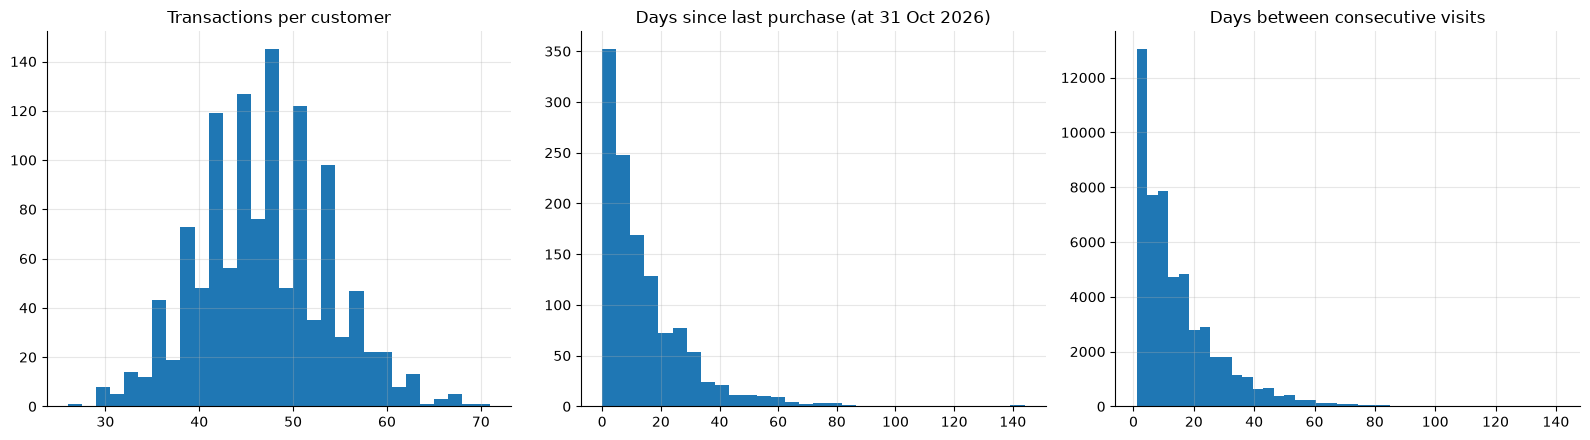


line items dated before signup: 12959 (12.1% of known-customer lines)
customers affected: 561


In [17]:
### Customer activity: frequency, recency, and gaps 

known = df[~df["is_guest"]]
end_date = df[DATE].max()

cust_t = known.groupby("customer_id").agg(first_purchase=(DATE, "min"), last_purchase=(DATE, "max"),
                                          transactions=(TXN, "nunique"), spend=(REV, "sum"))
cust_t["recency_days"] = (end_date - cust_t["last_purchase"]).dt.days
print("customers in table:", len(customers), "| with at least one purchase:", len(cust_t))
print(cust_t[["transactions", "spend", "recency_days"]].describe().round(1))

# Days between a customer's consecutive shopping days: how long is a normal gap?
visits = known.groupby(["customer_id", DATE]).size().reset_index()[["customer_id", DATE]].sort_values(["customer_id", DATE])
gaps = visits.groupby("customer_id")[DATE].diff().dt.days.dropna()
print("\ngap between visits (days), percentiles:")
print(gaps.quantile([.5, .75, .9, .95, .99]).round(0))
for x in [30, 60, 90]:
    print(f"customers with no purchase in the last {x} days: {(cust_t['recency_days'] > x).mean() * 100:.1f}%")

fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
ax[0].hist(cust_t["transactions"], bins=30); ax[0].set_title("Transactions per customer")
ax[1].hist(cust_t["recency_days"], bins=30); ax[1].set_title("Days since last purchase (at 31 Oct 2026)")
ax[2].hist(gaps, bins=40); ax[2].set_title("Days between consecutive visits")
save("06e_customer_activity")

# Data-quality note: purchases dated before the customer's signup date
bs = known[known["before_signup"]]
print("\nline items dated before signup: %d (%.1f%% of known-customer lines)" % (len(bs), len(bs) / len(known) * 100))
print("customers affected:", bs["customer_id"].nunique())

**Findings:**
No customer has actually left. All 1,200 customers have bought in the period, each with at least 26 transactions (median 46), and the median customer last bought 9.5 days before the end of the data. A normal gap between visits is 10 days (median), and 90% of gaps are 33 days or less, 95% are 42 or less, and 99% are 63 or less. Using a 30-day rule would call 10.8% of customers lapsed, but that is inside the normal gap range; a 60-day rule flags 1.5% (about 18 customers), and 90 days flags 0.1%. 
**Implication for the churn milestone:** 
The lapsed threshold should be set near the 95th to 99th percentile of gaps (about 45 to 60 days), and the lapsed group will be small, so the model must handle a heavily imbalanced target. 
**Data-quality note:** 12.1% of known-customer line items (12,959, from 561 customers) are dated before the customer's signup date. They are kept and flagged, and customer tenure features should not use signup date without handling this.

## Summary of findings and limitations

| Question  | Finding |

| Q1 Customer segments | Bronze, ages 35-44, and women lead only because they are the biggest groups; spend per buyer is about KES 29,000 to 31,000 in every segment, and Gold does not outspend Bronze. |
| Q2 Category by county  | Category mix is nearly identical in every county. Dry Foods is 36.9% of revenue. |
| Q3 Calendar and holidays | Tuesday (index 124) and Wednesday (114) are the strong days; Thursday to Sunday are 8% to 12% below average. No month-end effect. Holidays add only about 4% on average. |
| Q4 Payment methods | M-Pesa 66.8%, Cash 21.5%, Card 9.7%; the split is the same across counties, formats, and basket sizes. |
| Q5 Stores and counties | Store revenue is almost equal (9.6% to 10.3% each), so small stores earn far more per square foot (KES 49 to 55) than hypermarkets (7 to 9). Mombasa earns the most per resident. |
| Q6 Products | Pwani Cooking Oil is 23.3% of revenue. Bottom 20%: Festive Bread, Maziwa Milk, Mandazi. Fresh Produce has the best category margin (30.4%). |
| Q7 Promotions | Discounts of 10% to 20% cut profit per day by about 50% with no gain in transactions or gross sales per day. |
| Q8, Q9 Customer drift | No customer has stopped buying. A 45 to 60 day threshold is supported by the gap data and flags only 1.5% at 60 days. |
| Q10, Q11 Demand drive | Revenue is flat year on year (+0.1%). Day of week is the clear drivers; holidays are weak; inflation shows no clear link. |

**Limitations**
-Sales, customers, stores, products, and promotions are synthetic. Flat or perfectly even patterns (equal product sales, equal store revenue, identical payment splits) reflect how the data was generated, not real shopper behaviour.
- November and December 2026 were removed because they fall after the data date, so the observed period is 22 months.
- Inflation ends in September 2026, so October 2026 has no inflation value.
- Some purchases are dated before the customer's signup date; they are flagged, not removed.
- County population is for the store's county, but customers may live elsewhere.
- The promotion comparison is month-level only. It cannot separate a promotion's effect from other things that change in the same month.